Ziham Mahmud   
241002007   





In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df = pd.read_csv('/content/house_price_linear_regression.csv')

print("First five rows of the dataset:")
print(df.head())

First five rows of the dataset:
   area_sqft  bedrooms  age_years  distance_to_city_km  price_lakh
0        685         2          1                  2.3       54.01
1        720         3          2                  3.1       53.91
2        755         4          3                  3.9       62.52
3        790         1          4                  4.7       44.52
4        825         2          5                  5.5       53.42


Step 2   
Perform both simple and multiple Linear Regression if the dataset contains multiple numerical features.


Simple

In [ ]:
X = df[['area_sqft']]
y = df['price_lakh']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

y_pred_simple = simple_model.predict(X_test)

print("Simple Linear Regression")
print("Coefficient:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)
print("MAE:", mean_absolute_error(y_test, y_pred_simple))
print("MSE:", mean_squared_error(y_test, y_pred_simple))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_simple)))
print("R2 Score:", r2_score(y_test, y_pred_simple))

Simple Linear Regression
Coefficient: 0.04153535031375136
Intercept: 10.897174959569583
MAE: 7.940355646111522
MSE: 104.0444069233311
RMSE: 10.20021602336593
R2 Score: 0.7525718149547596


Multiple

In [ ]:
X = df[['area_sqft', 'bedrooms', 'age_years', 'distance_to_city_km']]
y = df['price_lakh']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

y_pred_multiple = multiple_model.predict(X_test)

print("Multiple Linear Regression")
print("Coefficients:", multiple_model.coef_)
print("Intercept:", multiple_model.intercept_)
print("MAE:", mean_absolute_error(y_test, y_pred_multiple))
print("MSE:", mean_squared_error(y_test, y_pred_multiple))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_multiple)))
print("R2 Score:", r2_score(y_test, y_pred_multiple))

Multiple Linear Regression
Coefficients: [ 0.04512281  5.85359618 -0.63473733 -0.87232311]
Intercept: 9.624612475462115
MAE: 1.9308779675907526
MSE: 5.152010957986667
RMSE: 2.269804167320755
R2 Score: 0.9877479937810864


Step 3   

Compare the performance of the models using MAE, MSE, RMSE, and 𝑅 2 Score.


In [ ]:
results = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'MAE': [
        mean_absolute_error(y_test, y_pred_simple),
        mean_absolute_error(y_test, y_pred_multiple)
    ],
    'MSE': [
        mean_squared_error(y_test, y_pred_simple),
        mean_squared_error(y_test, y_pred_multiple)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_simple)),
        np.sqrt(mean_squared_error(y_test, y_pred_multiple))
    ],
    'R2 Score': [
        r2_score(y_test, y_pred_simple),
        r2_score(y_test, y_pred_multiple)
    ]
})

print(results.round(4))

                        Model     MAE       MSE     RMSE  R2 Score
0    Simple Linear Regression  7.9404  104.0444  10.2002    0.7526
1  Multiple Linear Regression  1.9309    5.1520   2.2698    0.9877


Step 4   
Include visualizations such as:    
 4.1 Scatter plot of input feature and target variable    
 4.2 Regression line plot    
 4.3 Actual vs predicted value plot    
 4.4  Residual plot


4.1 Scatter plot of input feature and target variable

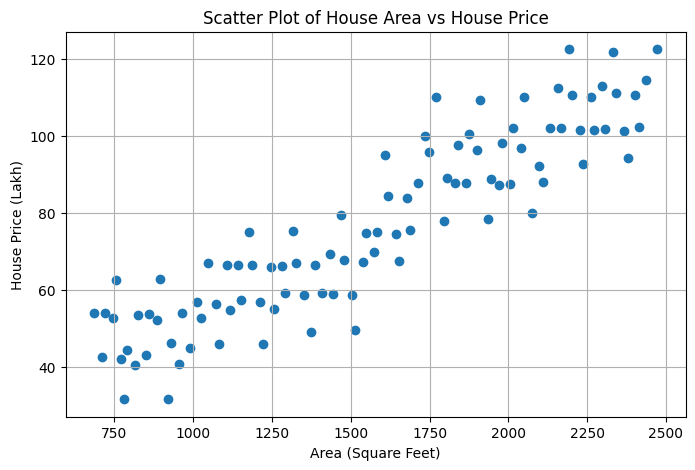

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df['area_sqft'], df['price_lakh'])
plt.xlabel('Area (Square Feet)')
plt.ylabel('House Price (Lakh)')
plt.title('Scatter Plot of House Area vs House Price')
plt.grid(True)
plt.show()

4.2 Regression line plot

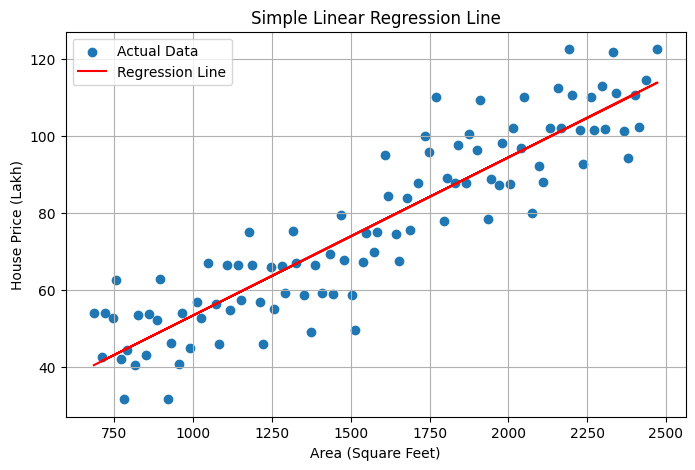

In [ ]:
import matplotlib.pyplot as plt

X = df[['area_sqft']]
y = df['price_lakh']

simple_model = LinearRegression()
simple_model.fit(X, y)

y_pred = simple_model.predict(X)

plt.figure(figsize=(8, 5))
plt.scatter(X['area_sqft'], y, label='Actual Data')
plt.plot(X['area_sqft'], y_pred, color='red', label='Regression Line')
plt.xlabel('Area (Square Feet)')
plt.ylabel('House Price (Lakh)')
plt.title('Simple Linear Regression Line')
plt.legend()
plt.grid(True)
plt.show()

4.3 Actual vs predicted value plot

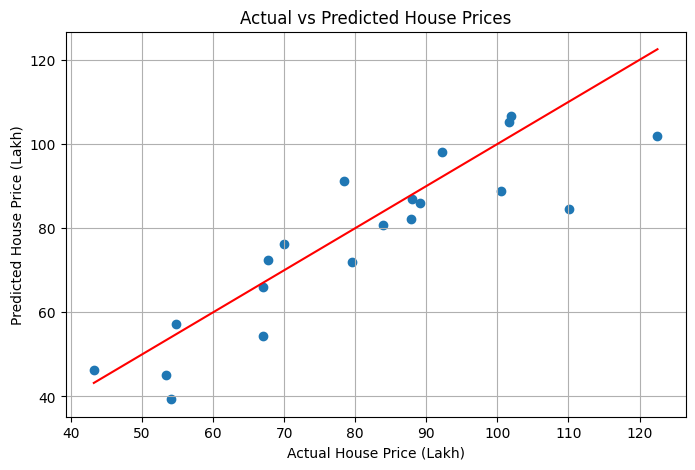

In [ ]:
import matplotlib.pyplot as plt

X = df[['area_sqft']]
y = df['price_lakh']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

y_pred = simple_model.predict(X_test)

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)
plt.xlabel('Actual House Price (Lakh)')
plt.ylabel('Predicted House Price (Lakh)')
plt.title('Actual vs Predicted House Prices')
plt.grid(True)
plt.show()

4.4  Residual plot

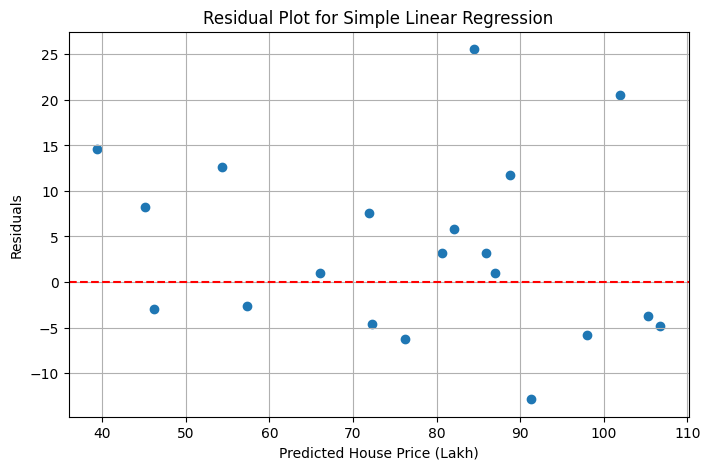

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df[['area_sqft']]
y = df['price_lakh']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

y_pred = simple_model.predict(X_test)

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted House Price (Lakh)')
plt.ylabel('Residuals')
plt.title('Residual Plot for Simple Linear Regression')
plt.grid(True)
plt.show()